In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import joblib

In [2]:
df = pd.read_csv(
    "../dataset/AquaSense_Feature_Engineered.csv"
)

df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (45864, 22)


,Date,Time,Consumption,Temperature,Rain,Sun,Hour,Timestamp,Day,Month,...,Weekday,Hour_sin,Hour_cos,Month_sin,Month_cos,Lag_1,Lag_24,Lag_168,Rolling_Mean_24,Rolling_Mean_168
0,2016-01-08,00:00-01:00,1025,5.5,0.0,0,0,2016-01-08 00:00:00,8,1,...,Friday,0.000000,1.000000,0.5,0.866025,1653.0,1007.0,1480.0,1999.416667,1956.035714
1,2016-01-08,01:00-02:00,605,5.6,0.0,0,1,2016-01-08 01:00:00,8,1,...,Friday,0.258819,0.965926,0.5,0.866025,1025.0,624.0,1362.0,2000.166667,1953.327381
2,2016-01-08,02:00-03:00,358,5.6,0.0,0,2,2016-01-08 02:00:00,8,1,...,Friday,0.500000,0.866025,0.5,0.866025,605.0,384.0,1296.0,1999.375000,1948.821429
3,2016-01-08,03:00-04:00,277,5.4,0.0,0,3,2016-01-08 03:00:00,8,1,...,Friday,0.707107,0.707107,0.5,0.866025,358.0,217.0,1096.0,1998.291667,1943.238095
4,2016-01-08,04:00-05:00,336,5.1,0.0,0,4,2016-01-08 04:00:00,8,1,...,Friday,0.866025,0.500000,0.5,0.866025,277.0,287.0,810.0,2000.791667,1938.363095


In [3]:
# Select input features
features = [
    "Hour",
    "Day",
    "Month",
    "Year",
    "DayOfWeek",
    "Temperature",
    "Rain",
    "Sun",
    "Hour_sin",
    "Hour_cos",
    "Month_sin",
    "Month_cos",
    "Lag_1",
    "Lag_24",
    "Lag_168",
    "Rolling_Mean_24",
    "Rolling_Mean_168"
]

X = df[features]

# Target variable
y = df["Consumption"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (45864, 17)
Target Shape: (45864,)


In [4]:
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Period:")
print(df["Timestamp"].iloc[0],
      "to",
      df["Timestamp"].iloc[split_index - 1])

print("\nTesting Period:")
print(df["Timestamp"].iloc[split_index],
      "to",
      df["Timestamp"].iloc[-1])

Training Records: 36691
Testing Records: 9173

Training Period:
2016-01-08 00:00:00 to 2020-03-15 18:00:00

Testing Period:
2020-03-15 19:00:00 to 2021-04-01 23:00:00


In [5]:
# Create Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model initialized!")

Random Forest model initialized!


In [6]:
# Train the model using training data

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [7]:
# Predict water consumption on testing data

y_pred = rf_model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions generated successfully!

First 10 Actual Values:
[2755 2474 1759 1515 1412 1509 1136  591  735 1210]

First 10 Predicted Values:
[2623.64 2516.22 1834.66 1585.94 1491.86 1202.37 1020.71  737.07  558.15
  836.28]


In [8]:
# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("----------------------------")

print("Mean Absolute Error (MAE):", round(mae, 2))

print("Root Mean Squared Error (RMSE):", round(rmse, 2))

print("R2 Score:", round(r2, 4))

print("R2 Score (%):", round(r2 * 100, 2), "%")

MODEL PERFORMANCE
----------------------------
Mean Absolute Error (MAE): 182.19
Root Mean Squared Error (RMSE): 250.99
R2 Score: 0.949
R2 Score (%): 94.9 %


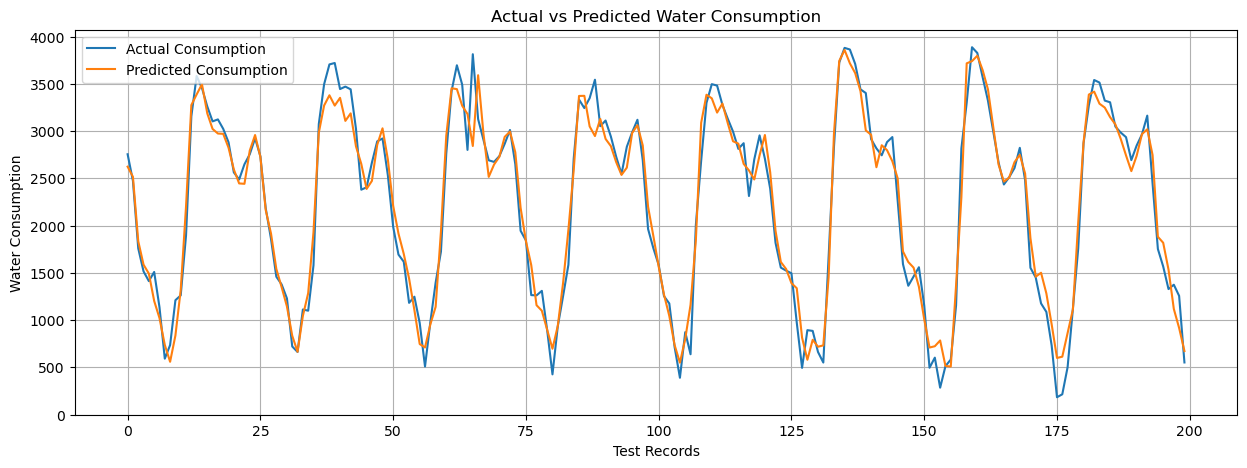

In [9]:
plt.figure(figsize=(15, 5))

plt.plot(
    y_test.values[:200],
    label="Actual Consumption"
)

plt.plot(
    y_pred[:200],
    label="Predicted Consumption"
)

plt.title("Actual vs Predicted Water Consumption")
plt.xlabel("Test Records")
plt.ylabel("Water Consumption")

plt.legend()
plt.grid(True)
plt.show()

In [11]:
print("MODEL PERFORMANCE")
print("----------------------------")

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Score (%):", round(r2 * 100, 2), "%")

MODEL PERFORMANCE
----------------------------
Mean Absolute Error (MAE): 182.19
Root Mean Squared Error (RMSE): 250.99
R2 Score: 0.949
R2 Score (%): 94.9 %


In [12]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

print("Gradient Boosting model initialized!")

Gradient Boosting model initialized!


In [13]:
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [14]:
gb_pred = gb_model.predict(X_test)

print("Gradient Boosting predictions generated!")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(gb_pred[:10])

Gradient Boosting predictions generated!

First 10 actual values:
[2755 2474 1759 1515 1412 1509 1136  591  735 1210]

First 10 predicted values:
[2574.69493631 2501.84898755 1780.40584111 1482.2037938  1372.37155899
 1260.43469722 1007.27031004  640.47230937  556.43393633  871.49110043]


In [15]:
gb_mae = mean_absolute_error(y_test, gb_pred)

gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))

gb_r2 = r2_score(y_test, gb_pred)

print("GRADIENT BOOSTING PERFORMANCE")
print("------------------------------")

print("MAE:", round(gb_mae, 2))
print("RMSE:", round(gb_rmse, 2))
print("R2 Score:", round(gb_r2, 4))
print("R2 Score (%):", round(gb_r2 * 100, 2), "%")

GRADIENT BOOSTING PERFORMANCE
------------------------------
MAE: 185.16
RMSE: 253.17
R2 Score: 0.9481
R2 Score (%): 94.81 %


In [16]:
import joblib

# Save the best forecasting model
joblib.dump(
    rf_model,
    "../models/AquaSense_Demand_Forecasting_Model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [17]:
joblib.dump(
    features,
    "../models/AquaSense_Model_Features.pkl"
)

print("Model features saved successfully!")

Model features saved successfully!
